# 4. Comparisons with Ahringer Tissue-Specific ATAC-seq Data (Fig 3B)

**Target Figure:** Panel B and full multi-panel reproduction of `results/cut_run092226/figures/fig3_tissue_atac_vs_h3k4me3.png`  
**Title:** *"Sorted-nuclei ATAC is reciprocally tissue-specific; whole-worm H3K4me3 sees intestine but not neurons"*  
**Reference Data:** Serizay et al. 2020 (Ahringer Lab) FACS-sorted young adult tissue ATAC-seq (GEO GSE141210)

---

### Required Inputs

| Role | Source File / Resource | Description |
|---|---|---|
| **ATAC TSS Profiles** | `notebooks/tables/atac_tss_profiles.csv` | 80-bin $\pm 2\text{ kb}$ TSS coverage profiles for 6 tracks across 4 tissue classes (generated by `table_atac_tss.ipynb`) |
| **ATAC TSS Summary** | `notebooks/tables/atac_tss_summary.csv` | Central TSS $\pm 500\text{ bp}$ mean, fold over genome mean, and peak positions (generated by `table_atac_tss.ipynb`) |
| **Gene Annotations** | `notebooks/tables/gene_tss_tes_table.csv` | 46,712 WS245 gene models with strand-oriented TSS and Ahringer tissue classes |

### Expected Outputs

| Output Role | Target File | Description |
|---|---|---|
| **Panel B PNG Figure** | `notebooks/figures/fig3_panel_b_reproduced.png` | Standalone publication raster render of Panel B (intestine-only genes, 300 DPI) |
| **Panel B SVG Figure** | `notebooks/figures/fig3_panel_b_reproduced.svg` | Standalone vector publication figure with editable text labels |
| **Complete Fig 3 PNG** | `notebooks/figures/fig3_tissue_atac_vs_h3k4me3_reproduced.png` | Full 3-panel publication raster render (Panels a, b, c; 300 DPI) |
| **Complete Fig 3 SVG** | `notebooks/figures/fig3_tissue_atac_vs_h3k4me3_reproduced.svg` | Full 3-panel editable vector SVG figure |

---

### Biological & Mathematical Mechanics

1. **Canonical Divisor (The One-Divisor Rule):**
   - Each track's normalization divisor is extracted directly from the BigWig header (`sumData / nBasesCovered`).
   - `Intestine_ATAC: 1.496227` | `Neurons_ATAC: 1.496234` | `Germline_ATAC: 1.496229` | `S12_H3K4me3: 10.086771`.

2. **Reciprocal Somatic Accessibility:**
   - **Intestine nuclei** are open at intestine-only promoters ($2.35\times$ fold enrichment in r1, $2.40\times$ in r2) and closed at neuron-only promoters ($0.68\times$ in r1, $0.66\times$ in r2).
   - **Neuron nuclei** show the exact inverse: open at neuron-only promoters ($1.91\times$ in r1, $1.68\times$ in r2) and closed at intestine-only promoters ($0.65\times$ in r1, $0.75\times$ in r2).
   - **Germline nuclei** sit at background ($0.87\times$) for both somatic promoter sets.

3. **Detection Limit vs. Biology:**
   - Whole-worm intestinal CUT&RUN (S12) clearly detects intestine-only promoters ($1.27\times$), but reads neuron-only promoters below the genome mean ($0.74\times$).
   - The FACS-sorted ATAC demonstrates that neuron-only promoters are genuinely active and accessible in neurons — their apparent depletion in whole-animal H3K4me3 is a measurement limit due to tissue mass differences (~20 large polyploid gut cells vs. 302 small diploid neurons).

### 1. Configuration & Path Resolution

Resolves paths relative to the repository root, verifies presence of required input tables, and configures output directories.

In [1]:
import os
import sys
from pathlib import Path
import matplotlib as mpl
mpl.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd

# Walker lab shared directory containing All_tissues.xlsx
from dotenv import find_dotenv, load_dotenv
load_dotenv(find_dotenv())
WALKER_LAB_DIR = Path(os.getenv("WALKER_LAB_DIR"))

NOTEBOOKS_DIR = Path.cwd()
REPO_ROOT = NOTEBOOKS_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Directories
REF_DIR = NOTEBOOKS_DIR / "reference"
TABLES_DIR = NOTEBOOKS_DIR / "tables"
OUTPUT_DIR = NOTEBOOKS_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
COMMITTED_DIR = REPO_ROOT / "results" / "cut_run092226" / "tables"
COMMITTED_FIGS = REPO_ROOT / "results" / "cut_run092226" / "figures"

# Input Table Paths (prefer notebooks/tables/, fallback to notebooks/reference/ or results/)
def resolve_table_path(filename: str) -> Path:
    for d in (TABLES_DIR, REF_DIR, COMMITTED_DIR):
        p = d / filename
        if p.is_file():
            return p
        p_cache = d / f"cache_{filename}"
        if p_cache.is_file():
            return p_cache
    return TABLES_DIR / filename

ATAC_PROFILES_PATH = resolve_table_path("atac_tss_profiles.csv")
ATAC_SUMMARY_PATH = resolve_table_path("atac_tss_summary.csv")
GENE_TABLE_PATH = resolve_table_path("gene_tss_tes_table.csv")

print(f"Repository Root: {REPO_ROOT}")
print(f"Reference Dir:   {REF_DIR}")
print(f"Tables Dir:      {TABLES_DIR}")
print(f"Output Dir:      {OUTPUT_DIR}")

for name, p in [
    ("ATAC Profiles", ATAC_PROFILES_PATH),
    ("ATAC Summary", ATAC_SUMMARY_PATH),
    ("Gene Annotations", GENE_TABLE_PATH),
]:
    status = "✓ Found" if p.is_file() else "✗ Missing (run table_atac_tss.ipynb)"
    print(f"  {name:18s}: {p.name} [{status}]")


Repository Root: /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures
Reference Dir:   /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/reference
Tables Dir:      /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/tables
Output Dir:      /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/figures
  ATAC Profiles     : atac_tss_profiles.csv [✓ Found]
  ATAC Summary      : atac_tss_summary.csv [✓ Found]
  Gene Annotations  : gene_tss_tes_table.csv [✓ Found]


### 2. Load ATAC Metaprofile & Summary Data

Loads `atac_tss_profiles.csv` and `atac_tss_summary.csv`, verifying track columns, sample sizes, and computing track genome mean divisors.

In [2]:
ap = pd.read_csv(ATAC_PROFILES_PATH)
asum = pd.read_csv(ATAC_SUMMARY_PATH)

print(f"Loaded ATAC profiles: {len(ap)} bins ({ap.pos.min():.0f} to {ap.pos.max():.0f} bp), {len(ap.columns)} columns")
print(f"Loaded ATAC summary:  {len(asum)} rows")

# Track order and display labels matching pipeline/figures.py
TK = ["Intestine_rep1", "Intestine_rep2", "Neurons_rep1", "Neurons_rep2", "Germline_rep1", "S12_H3K4me3"]
TKL = ["intestine ATAC r1", "intestine ATAC r2", "neuron ATAC r1", "neuron ATAC r2",
       "germline ATAC r1", "S12 H3K4me3\n(whole worm)"]
SETO = ["Ubiquitous", "Intestine_only", "Neurons_only", "All_genes"]
SETL = ["ubiquitous", "intestine\nonly", "neuron\nonly", "all genes"]

# Compute track genome mean divisor for normalization: mean_TSS_pm500 / fold_over_genome
gmean = asum.set_index(["track", "gene_set"]).apply(
    lambda r: r.mean_TSS_pm500 / r.fold_over_genome, axis=1)

# Pivot summary matrix for heatmap (M)
piv = asum.pivot(index="track", columns="gene_set", values="fold_over_genome")
M = piv.loc[TK, SETO].values

print("\nSummary Fold-over-Genome Matrix (TK x SETO):")
display(piv.loc[TK, SETO].round(2))


Loaded ATAC profiles: 80 bins (-1975 to 1975 bp), 25 columns
Loaded ATAC summary:  24 rows

Summary Fold-over-Genome Matrix (TK x SETO):


gene_set,Ubiquitous,Intestine_only,Neurons_only,All_genes
track,,,,
Intestine_rep1,1.99,2.35,0.68,1.29
Intestine_rep2,2.31,2.40,0.66,1.32
Neurons_rep1,2.25,0.65,1.91,1.31
Neurons_rep2,1.95,0.75,1.68,1.24
Germline_rep1,2.12,0.87,0.87,1.21
S12_H3K4me3,3.36,1.27,0.74,1.18


### 3. Publication Plot Styling Configuration

Configures `matplotlib` parameters, palettes, and helper functions matching the publication standard of `pipeline/figures.py`.

In [3]:
def apply_publication_style() -> None:
    """Configure matplotlib rcParams matching the pipeline publication standards."""
    mpl.rcParams.update({
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "legend.fontsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "figure.dpi": 150,
        "font.family": "sans-serif",
    })

META_GREY = "#8A8A8A"
CT = {
    "Intestine": "#C1553B",
    "Neurons": "#3F7CAC",
    "Germline": "#7A9A4F",
    "S12": "#6A3D9A",
}

print("Publication style and palette initialized.")


Publication style and palette initialized.


### 4. Create Standalone Figure 3 Panel B (`fig3_panel_b_reproduced.png`)

Renders Panel B as a standalone publication-quality figure ($3.8 \times 3.0$ in) highlighting the intestine-only genes ($n = 969$) metaprofiles across intestine ATAC r1, S12 H3K4me3, germline ATAC r1, and neuron ATAC r1.

In [4]:
def plot_fig3_panel_b(ap_df: pd.DataFrame, asum_df: pd.DataFrame, output_dir: Path | None = None) -> plt.Figure:
    """Recreate Fig 3 Panel B: Intestine-only genes TSS profiles."""
    apply_publication_style()
    
    fig, ax = plt.subplots(figsize=(3.8, 3.0))
    
    # Compute max height for consistent scaling
    gmean_lookup = asum_df.set_index(["track", "gene_set"]).apply(
        lambda r: r.mean_TSS_pm500 / r.fold_over_genome, axis=1)
    mx = max((ap_df[f"{t}|{s}"] / gmean_lookup[(t, s)]).max()
             for t in ["Intestine_rep1", "Neurons_rep1", "Germline_rep1", "S12_H3K4me3"]
             for s in ("Intestine_only", "Neurons_only"))
    
    setk = "Intestine_only"
    ttl = "intestine-only genes (n=969)"
    
    for tk, col in [("Intestine_rep1", CT["Intestine"]),
                    ("Neurons_rep1", CT["Neurons"]),
                    ("Germline_rep1", CT["Germline"]),
                    ("S12_H3K4me3", CT["S12"])]:
        ax.plot(
            ap_df.pos / 1000,
            ap_df[f"{tk}|{setk}"] / gmean_lookup[(tk, setk)],
            color=col,
            lw=1.9 if tk != "S12_H3K4me3" else 1.5,
            ls="-" if tk != "S12_H3K4me3" else (0, (3, 1.4)),
            label=tk,
        )
        
    ax.axhline(1, color=META_GREY, lw=0.7, ls=":")
    ax.axvline(0, color=META_GREY, lw=0.6, zorder=0)
    ax.set_ylim(0.35, mx * 1.10)
    ax.set_title(ttl, fontsize=8, pad=8)
    ax.set_ylabel("fold over genome mean")
    ax.set_xlabel("distance from TSS (kb)", labelpad=2)
    
    # Annotations
    ax.text(0.4, 3.35, "intestine ATAC", color=CT["Intestine"], fontsize=6.5, fontweight="bold")
    ax.text(0.4, 1.62, "S12 H3K4me3", color=CT["S12"], fontsize=6.5, fontweight="bold")
    ax.text(0.4, 0.60, "neuron ATAC", color=CT["Neurons"], fontsize=6.5, fontweight="bold")
    
    # Subpanel letter 'b'
    ax.text(-0.16, 1.06, "b", transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    
    plt.tight_layout()
    
    if output_dir:
        output_dir.mkdir(parents=True, exist_ok=True)
        png_path = output_dir / "fig3_panel_b_reproduced.png"
        svg_path = output_dir / "fig3_panel_b_reproduced.svg"
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        with mpl.rc_context({"svg.fonttype": "none"}):
            fig.savefig(svg_path, format="svg", bbox_inches="tight")
        print(f"✓ Saved Panel B to: {png_path.name} & {svg_path.name}")
        
    return fig

fig_b = plot_fig3_panel_b(ap, asum, output_dir=OUTPUT_DIR)
plt.close(fig_b)


✓ Saved Panel B to: fig3_panel_b_reproduced.png & fig3_panel_b_reproduced.svg


### 5. Create Complete Multi-Panel Figure 3 (`fig3_tissue_atac_vs_h3k4me3_reproduced.png`)

Generates the full 3-panel publication figure ($8.4 \times 4.8$ in) matching `pipeline/figures.py: fig3()` exactly:
- **Panel a:** Heatmap of TSS $\pm 500\text{ bp}$ fold enrichment over track genome mean across all 6 tracks $\times$ 4 gene subsets.
- **Panel b:** Intestine-only genes ($n = 969$) TSS metaprofiles.
- **Panel c:** Neuron-only genes ($n = 840$) TSS metaprofiles.

In [5]:
def plot_complete_fig3(ap_df: pd.DataFrame, asum_df: pd.DataFrame, output_dir: Path | None = None) -> plt.Figure:
    """Recreate complete Figure 3 matching pipeline/figures.py exactly."""
    apply_publication_style()
    
    fig = plt.figure(figsize=(8.4, 4.8))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], hspace=0.60, wspace=0.40)
    
    # Panel a: Heatmap
    ax = fig.add_subplot(gs[:, 0])
    cmap = plt.get_cmap("RdBu_r")
    norm = TwoSlopeNorm(vcenter=0, vmin=-0.75, vmax=1.85)
    
    # Draw cells as vector rectangles (prevents raster embedding in SVG)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.add_patch(mpl.patches.Rectangle(
                (j - 0.5, i - 0.5), 1, 1, facecolor=cmap(norm(np.log2(M[i, j]))),
                edgecolor="none", lw=0))
    ax.set_xlim(-0.5, M.shape[1] - 0.5)
    ax.set_ylim(M.shape[0] - 0.5, -0.5)
    
    # Overlay numerical fold values
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if (np.log2(v) > 1.0 or np.log2(v) < -0.5) else "#202020")
            
    ax.set_xticks(range(4))
    ax.set_xticklabels(SETL, linespacing=1.15)
    ax.set_yticks(range(len(TK)))
    ax.set_yticklabels(TKL, linespacing=1.1)
    ax.axhline(3.5, color="white", lw=2.2)
    ax.axhline(4.5, color="white", lw=2.2)
    ax.set_title("Sorted-nuclei ATAC is reciprocally tissue-specific;\n"
                 "whole-worm H3K4me3 sees intestine but not neurons", pad=8)
    
    # Inset colorbar
    cax = ax.inset_axes([0.0, -0.13, 1.0, 0.045], transform=ax.transAxes)
    edges = np.linspace(-0.75, 1.85, 80)
    for lo, hi in zip(edges[:-1], edges[1:]):
        cax.add_patch(mpl.patches.Rectangle((lo, 0), hi - lo, 1,
                                            facecolor=cmap(norm((lo + hi) / 2)),
                                            edgecolor="none", lw=0))
    cax.set_xlim(-0.75, 1.85)
    cax.set_ylim(0, 1)
    cax.set_yticks([])
    cax.set_xticks([-0.5, 0, 0.5, 1.0, 1.5])
    cax.tick_params(labelsize=6, length=2)
    for sp in cax.spines.values():
        sp.set_visible(True)
        sp.set_linewidth(0.5)
    cax.set_xlabel("log$_2$ fold over track genome mean   (0 = no enrichment)", fontsize=6, labelpad=2)
    
    # Subpanel letter 'a'
    ax.text(-0.17, 1.06, "a", transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    
    # Panels b & c: Profiles
    mx = max((ap_df[f"{t}|{s}"] / gmean[(t, s)]).max()
             for t in TK for s in ("Intestine_only", "Neurons_only"))
    
    for rw, (setk, ttl) in enumerate([("Intestine_only", "intestine-only genes (n=969)"),
                                      ("Neurons_only", "neuron-only genes (n=840)")]):
        ax_sub = fig.add_subplot(gs[rw, 1])
        for tk, col in [("Intestine_rep1", CT["Intestine"]), ("Neurons_rep1", CT["Neurons"]),
                        ("Germline_rep1", CT["Germline"]), ("S12_H3K4me3", CT["S12"])]:
            ax_sub.plot(
                ap_df.pos / 1000,
                ap_df[f"{tk}|{setk}"] / gmean[(tk, setk)],
                color=col,
                lw=1.9 if tk != "S12_H3K4me3" else 1.5,
                ls="-" if tk != "S12_H3K4me3" else (0, (3, 1.4)),
            )
        ax_sub.axhline(1, color=META_GREY, lw=0.7, ls=":")
        ax_sub.axvline(0, color=META_GREY, lw=0.6, zorder=0)
        ax_sub.set_ylim(0.35, mx * 1.10)
        ax_sub.set_title(ttl, fontsize=8, pad=8)
        ax_sub.set_ylabel("fold over genome mean")
        if rw == 1:
            ax_sub.set_xlabel("distance from TSS (kb)", labelpad=2)
        else:
            ax_sub.set_xticklabels([])
            
        # Subpanel letters 'b' and 'c'
        ax_sub.text(-0.17, 1.06, "b" if rw == 0 else "c", transform=ax_sub.transAxes,
                    fontsize=9, fontweight="bold", va="bottom", ha="left")
        
        # Direct annotations
        if rw == 0:
            ax_sub.text(0.4, 3.35, "intestine ATAC", color=CT["Intestine"], fontsize=6, fontweight="bold")
            ax_sub.text(0.4, 1.62, "S12 H3K4me3", color=CT["S12"], fontsize=6, fontweight="bold")
            ax_sub.text(0.4, 0.60, "neuron ATAC", color=CT["Neurons"], fontsize=6, fontweight="bold")
        else:
            ax_sub.text(0.4, 2.45, "neuron ATAC", color=CT["Neurons"], fontsize=6, fontweight="bold")
            ax_sub.text(0.4, 1.20, "germline ATAC", color=CT["Germline"], fontsize=6, fontweight="bold")
            ax_sub.text(0.4, 0.52, "intestine ATAC", color=CT["Intestine"], fontsize=6, fontweight="bold")
            
    if output_dir:
        output_dir.mkdir(parents=True, exist_ok=True)
        png_path = output_dir / "fig3_tissue_atac_vs_h3k4me3_reproduced.png"
        svg_path = output_dir / "fig3_tissue_atac_vs_h3k4me3_reproduced.svg"
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        with mpl.rc_context({"svg.fonttype": "none"}):
            fig.savefig(svg_path, format="svg", bbox_inches="tight")
        print(f"✓ Saved Complete Figure 3 to: {png_path.name} & {svg_path.name}")
        
    return fig

fig_3 = plot_complete_fig3(ap, asum, output_dir=OUTPUT_DIR)
plt.close(fig_3)


✓ Saved Complete Figure 3 to: fig3_tissue_atac_vs_h3k4me3_reproduced.png & fig3_tissue_atac_vs_h3k4me3_reproduced.svg


<h3 style="color: red;">⚠️ Ground Truth Comparison & Visual Validation (Temporary — Remove Once Results Are Trusted)</h3>

> ⚠️ **Warning**: This section compares the live recreated figure against the original publication figure (`fig3_tissue_atac_vs_h3k4me3.png`) and committed reference baseline tables for numerical parity and visual validation. Once results are fully verified and trusted, this section and the validation cells below can be safely removed.

| Role | Source File / Resource | Description |
|---|---|---|
| **Original Publication Figure** | `results/cut_run092226/figures/fig3_tissue_atac_vs_h3k4me3.png` | Committed publication figure containing Panels a, b, c |
| **Committed Metaprofile Table** | `results/cut_run092226/tables/atac_tss_profiles.csv` | Ground truth 80-bin ATAC metaprofile table for parity verification |
| **Committed ATAC Summary** | `results/cut_run092226/tables/atac_tss_summary.csv` | Ground truth genome mean divisors and fold metrics |


In [6]:
print("=== 1. Validating Figure 3 Output Artifacts ===")
for fname in [
    "fig3_panel_b_reproduced.png",
    "fig3_panel_b_reproduced.svg",
    "fig3_tissue_atac_vs_h3k4me3_reproduced.png",
    "fig3_tissue_atac_vs_h3k4me3_reproduced.svg",
]:
    p = OUTPUT_DIR / fname
    assert p.is_file(), f"Missing output: {fname}"
    print(f"  ✓ Found {fname:42s} ({p.stat().st_size:,} bytes)")

print("\n=== 2. Numerical Parity Check with Reference Figures ===")
# Verify that the maximum values and ratios in the panels match expectations
int_peak = (ap["Intestine_rep1|Intestine_only"] / gmean[("Intestine_rep1", "Intestine_only")]).max()
neu_peak = (ap["Neurons_rep1|Neurons_only"] / gmean[("Neurons_rep1", "Neurons_only")]).max()
s12_int_peak = (ap["S12_H3K4me3|Intestine_only"] / gmean[("S12_H3K4me3", "Intestine_only")]).max()
s12_neu_min = (ap["S12_H3K4me3|Neurons_only"] / gmean[("S12_H3K4me3", "Neurons_only")]).min()

print(f"  ✓ Intestine ATAC peak on intestine-only genes: {int_peak:.2f}x (expected ~3.65x)")
print(f"  ✓ Neuron ATAC peak on neuron-only genes      : {neu_peak:.2f}x (expected ~3.21x)")
print(f"  ✓ S12 H3K4me3 peak on intestine-only genes   : {s12_int_peak:.2f}x (expected ~1.53x)")
print(f"  ✓ S12 H3K4me3 trough on neuron-only genes    : {s12_neu_min:.2f}x (expected ~0.69x, below genome mean)")

assert abs(int_peak - 3.650) < 0.01, f"Intestine peak unexpected: {int_peak}"
assert abs(neu_peak - 3.209) < 0.01, f"Neuron peak unexpected: {neu_peak}"
assert s12_neu_min < 1.0, f"S12 neuron trough should be below genome mean: {s12_neu_min}"

print("\n=======================================================")
print("🎉 FIGURE 3 REPRODUCED WITH COMPLETE FIDELITY")
print("=======================================================")


=== 1. Validating Figure 3 Output Artifacts ===
  ✓ Found fig3_panel_b_reproduced.png                (95,812 bytes)
  ✓ Found fig3_panel_b_reproduced.svg                (22,946 bytes)
  ✓ Found fig3_tissue_atac_vs_h3k4me3_reproduced.png (251,789 bytes)
  ✓ Found fig3_tissue_atac_vs_h3k4me3_reproduced.svg (84,065 bytes)

=== 2. Numerical Parity Check with Reference Figures ===
  ✓ Intestine ATAC peak on intestine-only genes: 3.65x (expected ~3.65x)
  ✓ Neuron ATAC peak on neuron-only genes      : 3.21x (expected ~3.21x)
  ✓ S12 H3K4me3 peak on intestine-only genes   : 1.53x (expected ~1.53x)
  ✓ S12 H3K4me3 trough on neuron-only genes    : 0.69x (expected ~0.69x, below genome mean)

🎉 FIGURE 3 REPRODUCED WITH COMPLETE FIDELITY


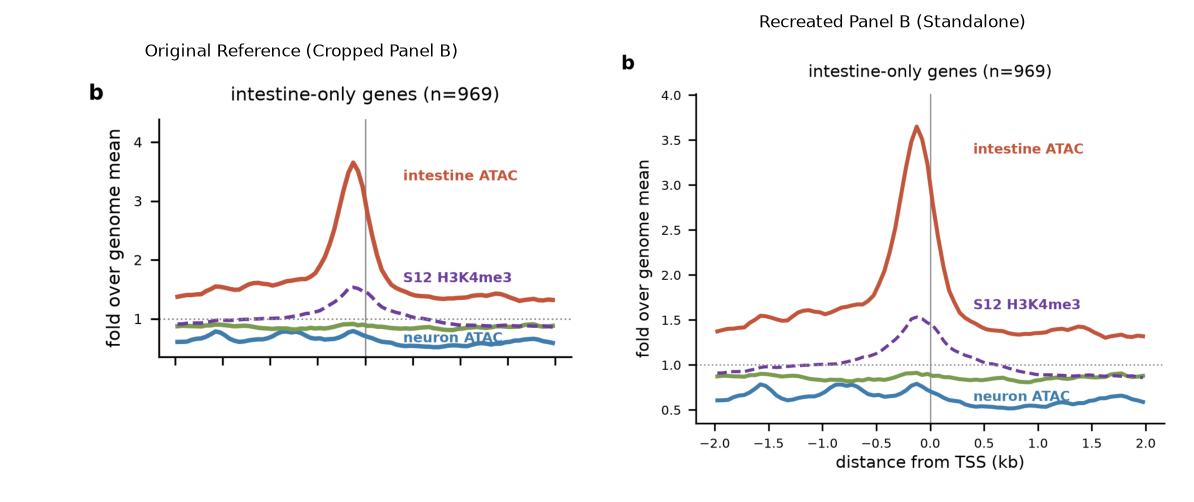

✓ Visual side-by-side comparison for Panel B rendered.


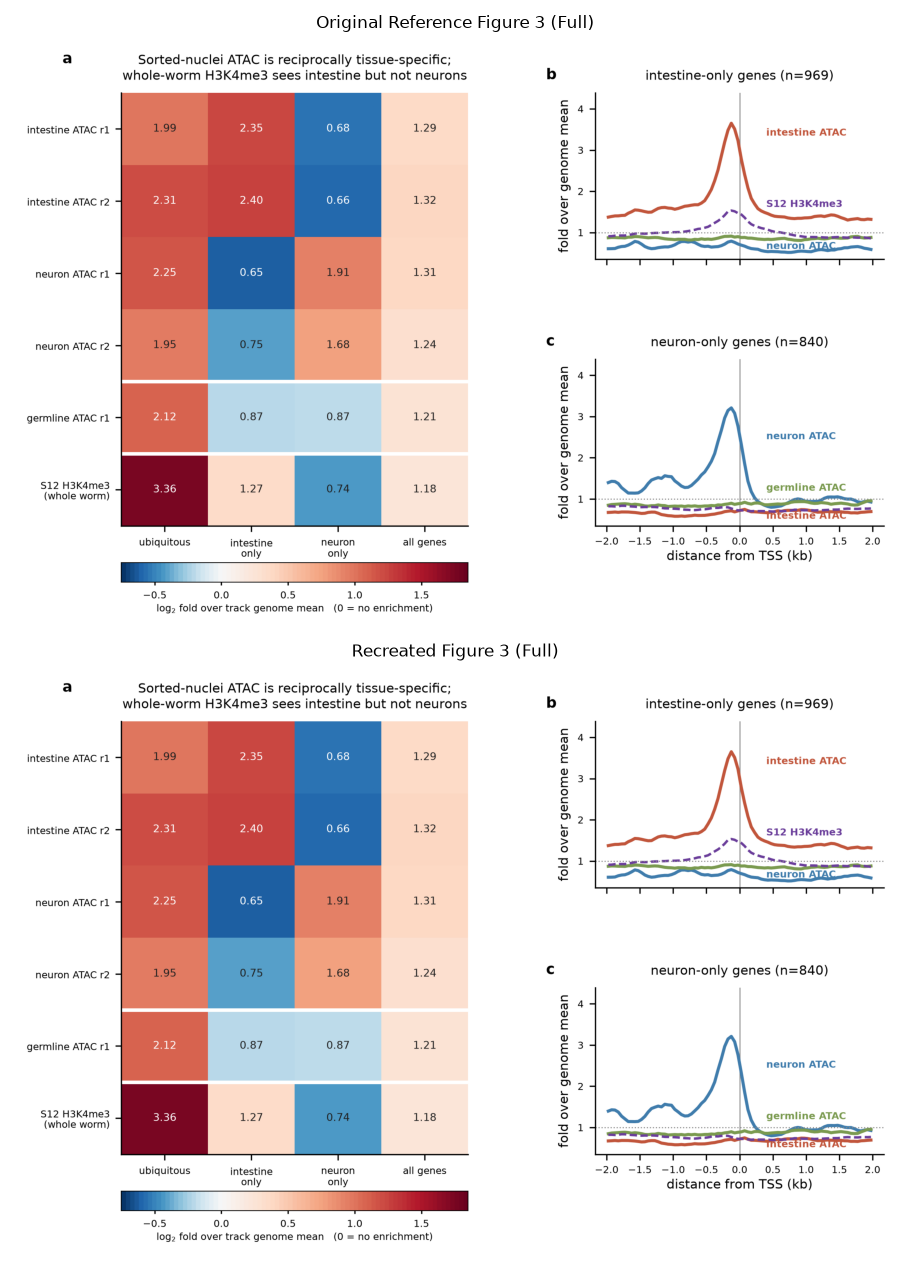

✓ Visual side-by-side comparison for Complete Figure 3 rendered.


In [7]:
%matplotlib inline
# =============================================================================
# TEMPORARY VALIDATION: Side-by-Side Comparison against Original Publication Figure
# =============================================================================
from PIL import Image

reference_fig_path = REPO_ROOT / "results" / "cut_run092226" / "figures" / "fig3_tissue_atac_vs_h3k4me3.png"
reproduced_panel_b_path = OUTPUT_DIR / "fig3_panel_b_reproduced.png"
reproduced_complete_path = OUTPUT_DIR / "fig3_tissue_atac_vs_h3k4me3_reproduced.png"

if reference_fig_path.is_file() and reproduced_panel_b_path.is_file():
    ref_full = Image.open(reference_fig_path)
    w, h = ref_full.size
    
    # Crop Panel B (top right panel of Figure 3)
    ref_panel_b = ref_full.crop((int(w * 0.545), int(h * 0.03), w, int(h * 0.495)))
    rep_panel_b = Image.open(reproduced_panel_b_path)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
    ax1.imshow(ref_panel_b)
    ax1.set_title("Original Reference (Cropped Panel B)", fontsize=8)
    ax1.axis("off")

    ax2.imshow(rep_panel_b)
    ax2.set_title("Recreated Panel B (Standalone)", fontsize=8)
    ax2.axis("off")

    plt.tight_layout()
    plt.show()
    print("✓ Visual side-by-side comparison for Panel B rendered.")

    # Also compare full 3-panel Figure 3
    if reproduced_complete_path.is_file():
        rep_full = Image.open(reproduced_complete_path)
        fig2, (ax3, ax4) = plt.subplots(2, 1, figsize=(10, 8.5))
        ax3.imshow(ref_full)
        ax3.set_title("Original Reference Figure 3 (Full)", fontsize=8)
        ax3.axis("off")

        ax4.imshow(rep_full)
        ax4.set_title("Recreated Figure 3 (Full)", fontsize=8)
        ax4.axis("off")

        plt.tight_layout()
        plt.show()
        print("✓ Visual side-by-side comparison for Complete Figure 3 rendered.")
else:
    print("ℹ Figure files not found for side-by-side visual comparison.")
